In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
df = pd.read_csv("https://raw.githubusercontent.com/Shreyagupta-31/Zomato-Data-Analysis/main/Zomato-data-.csv")
print(df.head())

                    name online_order book_table   rate  votes  \
0                  Jalsa          Yes        Yes  4.1/5    775   
1         Spice Elephant          Yes         No  4.1/5    787   
2        San Churro Cafe          Yes         No  3.8/5    918   
3  Addhuri Udupi Bhojana           No         No  3.7/5     88   
4          Grand Village           No         No  3.8/5    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [11]:
def handleRate(value):
    value=str(value).split('/')
    value=value[0];
    return float(value)

df['rate']=df['rate'].apply(handleRate)
print(df.head())

                    name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


In [13]:
print(df.isnull().sum())

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64


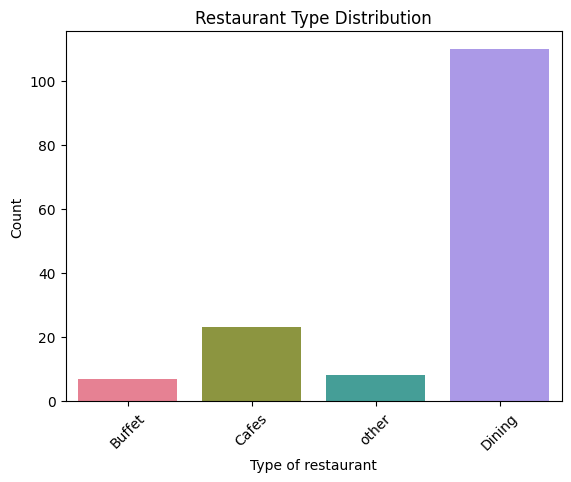

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get unique categories
unique_types = df['listed_in(type)'].unique()

# Create a color palette with a different color for each category
palette = sns.color_palette("husl", len(unique_types))

# Plot with hue and disable legend to avoid duplication
sns.countplot(
    x='listed_in(type)',
    hue='listed_in(type)',   # ✅ required for custom palette
    data=df,
    palette=dict(zip(unique_types, palette)),
    legend=False             # ✅ removes extra legend
)

plt.xlabel("Type of restaurant")
plt.ylabel("Count")
plt.title("Restaurant Type Distribution")
plt.xticks(rotation=45)  # optional for readability
plt.show()


Text(0, 0.5, 'Votes')

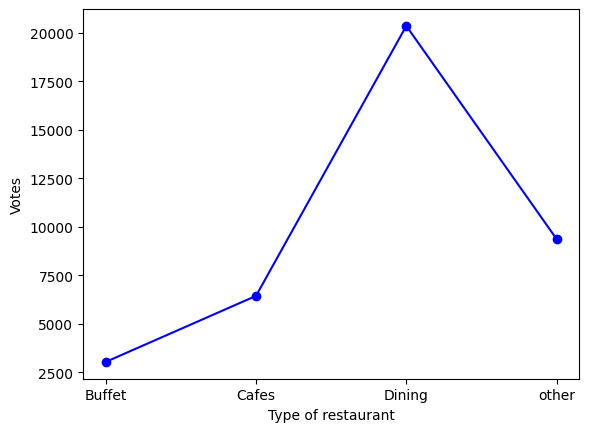

In [15]:
grouped_data = df.groupby('listed_in(type)')['votes'].sum()
result = pd.DataFrame({'votes': grouped_data})
plt.plot(result, c='blue', marker='o')
plt.xlabel('Type of restaurant')
plt.ylabel('Votes')

Restaurant(s) with the maximum votes:
                 name  votes
38  Empire Restaurant   4884


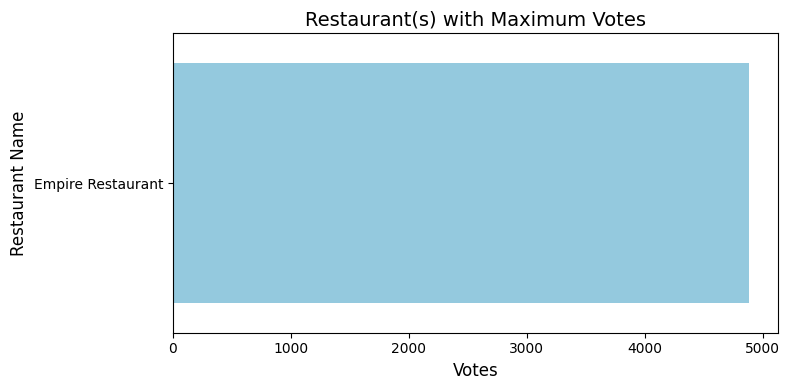

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find max votes and restaurant(s)
max_votes = df['votes'].max()
top_restaurants = df.loc[df['votes'] == max_votes, ['name', 'votes']]

print("Restaurant(s) with the maximum votes:")
print(top_restaurants)

# Horizontal bar chart (fixed for seaborn >=0.14)
plt.figure(figsize=(8,4))
sns.barplot(
    x='votes',
    y='name',
    data=top_restaurants,
    color="skyblue"   # use a single color instead of palette
)

plt.title('Restaurant(s) with Maximum Votes', fontsize=14)
plt.xlabel('Votes', fontsize=12)
plt.ylabel('Restaurant Name', fontsize=12)
plt.tight_layout()
plt.show()



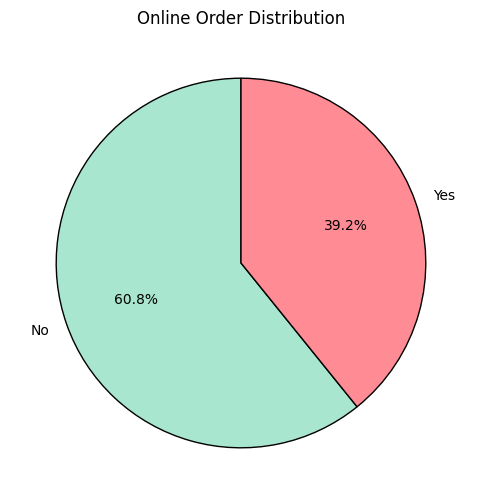

In [17]:
import matplotlib.pyplot as plt

# Count values
order_counts = df['online_order'].value_counts()

# Plot pie chart
plt.figure(figsize=(6,6))
order_counts.plot.pie(
    autopct='%1.1f%%',    # show percentages
    startangle=90,        # rotate start
    colors=['#a8e6cf', '#ff8b94'],  # custom colors (optional)
    wedgeprops=dict(edgecolor='black') # add border
)

plt.title("Online Order Distribution")
plt.ylabel("")  # remove y-label for cleaner look
plt.show()


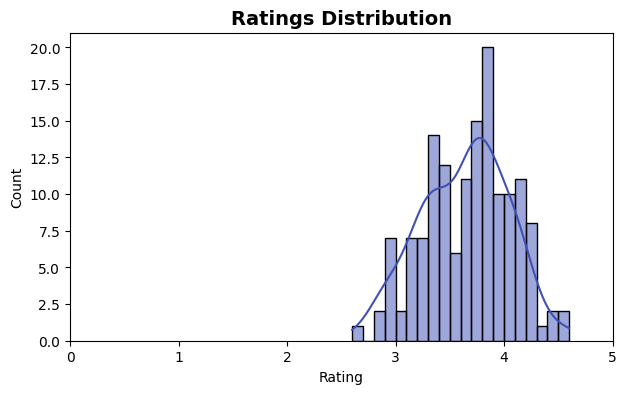

In [18]:
plt.figure(figsize=(7,4))
sns.histplot(df['rate'], bins=20, kde=True, color="#3f51b5", edgecolor="black")
plt.title("Ratings Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xlim(0,5)
plt.show()


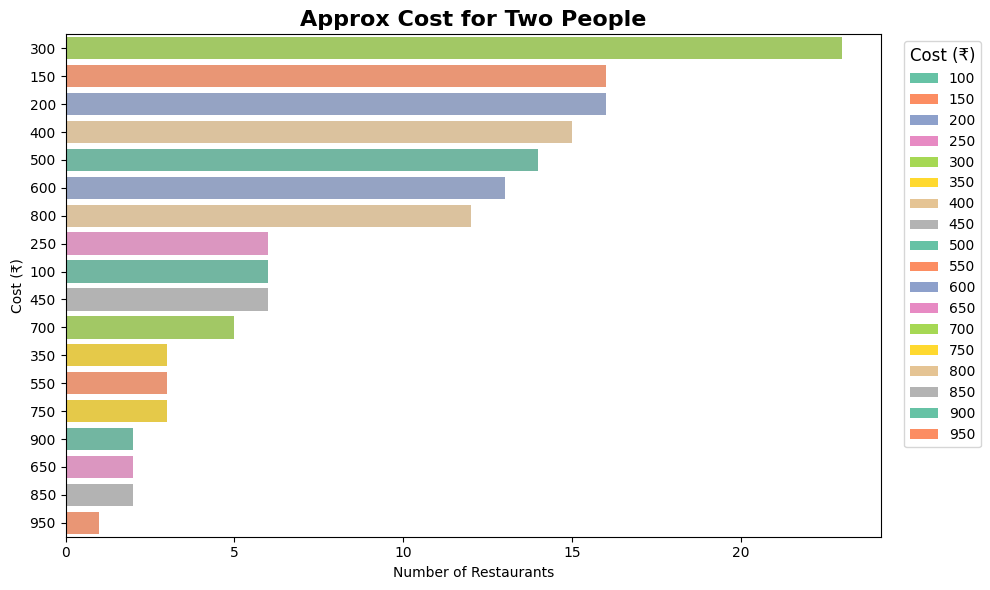

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Ensure all categories are strings
df['approx_cost(for two people)'] = df['approx_cost(for two people)'].astype(str)

# Get unique cost categories and sort
cost_categories = sorted(df['approx_cost(for two people)'].unique())

# Generate colors (use tab20 for more than 10 categories)
colors = sns.color_palette("Set2", len(cost_categories))

# Plot with hue and legend=False to satisfy Seaborn 0.14+
plt.figure(figsize=(10,6))
sns.countplot(
    y='approx_cost(for two people)',
    hue='approx_cost(for two people)',   # ✅ required for palette
    data=df,
    order=df['approx_cost(for two people)'].value_counts().index,
    palette=dict(zip(cost_categories, colors)),
    legend=False                         # ✅ suppress automatic legend
)

plt.title("Approx Cost for Two People", fontsize=16, fontweight="bold")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cost (₹)")

# Create a manual legend
legend_elements = [Patch(facecolor=colors[i], label=cost_categories[i]) for i in range(len(cost_categories))]
plt.legend(handles=legend_elements, title="Cost (₹)", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, title_fontsize=12)

plt.tight_layout()
plt.show()


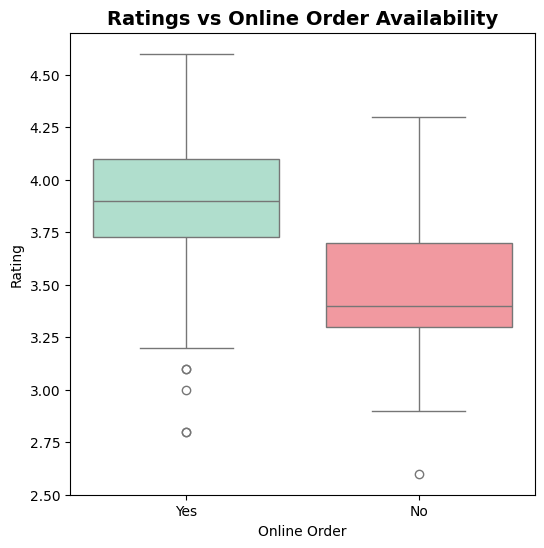

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
sns.boxplot(
    x='online_order',
    y='rate',
    hue='online_order',             # needed for palette
    data=df,
    palette=["#a8e6cf", "#ff8b94"],  # pastel green & pastel pink
    legend=False                    # removes redundant legend
)

plt.title("Ratings vs Online Order Availability", fontsize=14, fontweight='bold')
plt.xlabel("Online Order")
plt.ylabel("Rating")
plt.show()


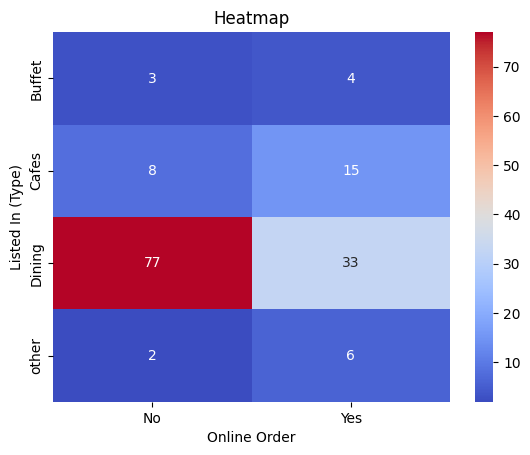

In [21]:

pivot_table = df.pivot_table(index='listed_in(type)', columns='online_order', aggfunc='size', fill_value=0)
sns.heatmap(pivot_table, annot=True, cmap='coolwarm', fmt='d')
plt.title('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Listed In (Type)')
plt.show()


In [22]:

import pandas as pd

url = "https://raw.githubusercontent.com/Shreyagupta-31/Zomato-Data-Analysis/main/Zomato-data-.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (148, 7)


,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [23]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (148, 7)

Column names:
['name', 'online_order', 'book_table', 'rate', 'votes', 'approx_cost(for two people)', 'listed_in(type)']

Missing values:
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

Data types:
name                           object
online_order                   object
book_table                     object
rate                           object
votes                           int64
approx_cost(for two people)     int64
listed_in(type)                object
dtype: object
